In [3]:
import cv2
import numpy as np
import pandas as pd
import random
import math
from tqdm import tqdm
import matplotlib.pyplot as plt
IMG_SIZE=28
def blank_image():
    return np.zeros((IMG_SIZE,IMG_SIZE),dtype=np.uint8)
def draw_triangle():
    img=blank_image()
    size=random.randint(10,18)
    cx=random.randint(12,16)
    cy=random.randint(12,16)
    h=int(size*0.87)
    pts=np.array([
        [cx,cy-h//2],
        [cx-size//2,cy+h//2],
        [cx+size//2,cy+h//2]
    ],dtype=np.int32)
    cv2.fillPoly(img,[pts],255)
    return img
def draw_square():
    img=blank_image()
    side=random.randint(10,18)
    x=random.randint(4,IMG_SIZE-side-4)
    y=random.randint(4,IMG_SIZE-side-4)
    cv2.rectangle(img,(x,y),(x+side,y+side),255,-1)
    return img
def draw_circle():
    img=blank_image()
    r=random.randint(5,9)
    cx=random.randint(r+2,IMG_SIZE-r-2)
    cy=random.randint(r+2,IMG_SIZE-r-2)
    cv2.circle(img,(cx,cy),r,255,-1)
    return img

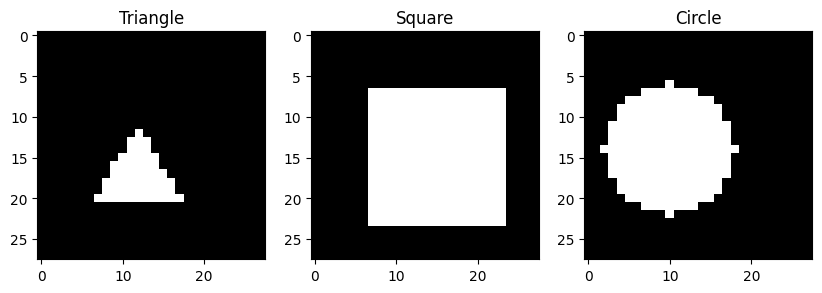

In [4]:
triangle=draw_triangle()
square=draw_square()
circle=draw_circle()
plt.figure(figsize=(10,3))
plt.subplot(131)
plt.imshow(triangle,cmap='gray')
plt.title("Triangle")
plt.subplot(132)
plt.imshow(square,cmap='gray')
plt.title("Square")
plt.subplot(133)
plt.imshow(circle,cmap='gray')
plt.title("Circle")
plt.show()

In [5]:
import cv2
import numpy as np
import math
def extract_features(img):
    img=img.astype(np.uint8)
    area=np.sum(img==255)
    gx=cv2.Sobel(img,cv2.CV_64F,1,0,ksize=3)
    gy=cv2.Sobel(img,cv2.CV_64F,0,1,ksize=3)
    magnitude=np.sqrt(gx**2+gy**2)
    magnitude=np.clip(magnitude,0,255).astype(np.uint8)
    edge=(magnitude>0).astype(np.uint8)*255
    edge_count=int(np.sum(edge==255))
    edge_sum=int(np.sum(magnitude))
    ys,xs=np.where(img==255)
    if len(xs)==0:
        width=0
        height=0
    else:
        width=int(xs.max()-xs.min()+1)
        height=int(ys.max()-ys.min()+1)
    if height==0:
        aspect_ratio=0
    else:
        aspect_ratio=int((width*100)/height)
    if edge_count==0:
        circularity=0
    else:
        circularity=int((4*math.pi*area*1000)/(edge_count*edge_count))
    if width*height==0:
        fill_ratio=0
    else:
        fill_ratio=int((area*1000)/(width*height))
    return [
        edge_count,
        edge_sum,
        area,
        width,
        height,
        aspect_ratio,
        circularity,
        fill_ratio
    ]

In [6]:
print("Triangle")
print(extract_features(triangle))
print()
print("Square")
print(extract_features(square))
print()
print("Circle")
print(extract_features(circle))

Triangle
[77, 19635, np.int64(54), 11, 9, 122, 114, 545]

Square
[136, 34680, np.int64(289), 17, 17, 100, 196, 1000]

Circle
[132, 33660, np.int64(197), 17, 17, 100, 142, 681]


In [7]:
import pandas as pd
from tqdm import tqdm
dataset=[]
NUM_SAMPLES=1000

for _ in tqdm(range(NUM_SAMPLES),desc="Triangle"):
    img=draw_triangle()
    f=extract_features(img)
    f.append(0)
    dataset.append(f)

for _ in tqdm(range(NUM_SAMPLES),desc="Square"):
    img=draw_square()
    f=extract_features(img)
    f.append(1)
    dataset.append(f)

for _ in tqdm(range(NUM_SAMPLES),desc="Circle"):
    img=draw_circle()
    f=extract_features(img)
    f.append(2)
    dataset.append(f)

columns=[
    "edge_count",
    "edge_sum",
    "area",
    "bbox_width",
    "bbox_height",
    "aspect_ratio",
    "circularity",
    "fill_ratio",
    "label"
]

df=pd.DataFrame(dataset,columns=columns)
df.to_csv("shape_dataset.csv",index=False)

print(df.head())
print()
print("Dataset shape:",df.shape)

Circle: 100%|██████████| 1000/1000 [00:00<00:00, 10184.21it/s]

   edge_count  edge_sum  area  bbox_width  bbox_height  aspect_ratio  \
0         109     27795   104          15           13           115   
1         117     29835   117          17           13           130   
2         125     31875   135          17           15           113   
3          93     23715    77          13           11           118   
4         133     33915   150          19           15           126   

   circularity  fill_ratio  label  
0          109         533      0  
1          107         529      0  
2          108         529      0  
3          111         538      0  
4          106         526      0  

Dataset shape: (3000, 9)


In [8]:
print(df.describe())

        edge_count      edge_sum        area   bbox_width  bbox_height  \
count  3000.000000   3000.000000  3000.00000  3000.000000  3000.000000   
mean    113.097000  28839.735000   161.79900    14.848667    14.025333   
std      21.517077   5486.854536    80.20681     2.654326     2.825129   
min      77.000000  19635.000000    54.00000    11.000000     9.000000   
25%      96.000000  24480.000000   104.00000    13.000000    12.000000   
50%     115.000000  29325.000000   144.00000    15.000000    13.000000   
75%     132.000000  33660.000000   197.00000    17.000000    16.000000   
max     152.000000  38760.000000   361.00000    19.000000    19.000000   

       aspect_ratio  circularity   fill_ratio        label  
count   3000.000000  3000.000000  3000.000000  3000.000000  
mean     106.673667   149.453000   736.778667     1.000000  
std        9.944486    35.587872   194.977374     0.816633  
min      100.000000   106.000000   526.000000     0.000000  
25%      100.000000   111.00

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [10]:
df=pd.read_csv("shape_dataset.csv")
df.head()

,edge_count,edge_sum,area,bbox_width,bbox_height,aspect_ratio,circularity,fill_ratio,label
0,109,27795,104,15,13,115,109,533,0
1,117,29835,117,17,13,130,107,529,0
2,125,31875,135,17,15,113,108,529,0
3,93,23715,77,13,11,118,111,538,0
4,133,33915,150,19,15,126,106,526,0


In [11]:
X=df.drop("label",axis=1)
y=df["label"]

In [12]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [13]:
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [14]:
from sklearn.neural_network import MLPClassifier

model=MLPClassifier(
    hidden_layer_sizes=(10,6),
    activation="relu",
    solver="adam",
    max_iter=5000,
    learning_rate_init=0.001,
    random_state=42
)

model.fit(X_train,y_train)

MLPClassifier(hidden_layer_sizes=(10, 6), max_iter=5000, random_state=42)

In [15]:
print(model.coefs_[0].shape)
print(model.coefs_[1].shape)
print(model.coefs_[2].shape)

print(model.intercepts_[0].shape)
print(model.intercepts_[1].shape)
print(model.intercepts_[2].shape)

(8, 10)
(10, 6)
(6, 3)
(10,)
(6,)
(3,)


In [16]:
train_acc=model.score(X_train,y_train)
test_acc=model.score(X_test,y_test)
print("Train Accuracy =",train_acc)
print("Test Accuracy =",test_acc)

Train Accuracy = 1.0
Test Accuracy = 1.0


In [17]:
pred=model.predict(X_test)
print(confusion_matrix(y_test,pred))

[[200   0   0]
 [  0 200   0]
 [  0   0 200]]


In [18]:
print(classification_report(y_test,pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       200
           1       1.00      1.00      1.00       200
           2       1.00      1.00      1.00       200

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600



In [19]:
import numpy as np
print("===== SCALER MEAN =====")
print(np.round(scaler.mean_,6))
print("\n===== SCALER SCALE =====")
print(np.round(scaler.scale_,6))
W1=np.round(model.coefs_[0]*1000).astype(int)
W2=np.round(model.coefs_[1]*1000).astype(int)
W3=np.round(model.coefs_[2]*1000).astype(int)
B1=np.round(model.intercepts_[0]*1000).astype(int)
B2=np.round(model.intercepts_[1]*1000).astype(int)
B3=np.round(model.intercepts_[2]*1000).astype(int)
print("\n===== W1 =====")
print(W1)
print("\n===== B1 =====")
print(B1)
print("\n===== W2 =====")
print(W2)
print("\n===== B2 =====")
print(B2)
print("\n===== W3 =====")
print(W3)
print("\n===== B3 =====")
print(B3)

===== SCALER MEAN =====
[1.13093333e+02 2.88388000e+04 1.61826667e+02 1.48495830e+01
 1.40237500e+01 1.06697083e+02 1.49443750e+02 7.36712083e+02]

===== SCALER SCALE =====
[2.15527750e+01 5.49595770e+03 8.02944060e+01 2.65947200e+00
 2.82737000e+00 9.96687800e+00 3.55784840e+01 1.94953251e+02]

===== W1 =====
[[-114  428  362  453 -505 -369 -437  404  144  427]
 [-523  450  478    7 -475 -337 -153   10  -51  -54]
 [-215 -479 -468  251 -311   52   58 -127 -114 -474]
 [ 270 -377 -313  688  557  623 -374 -445  337  197]
 [-293 -160 -561  797 -398   52  -38  104  114 -286]
 [ 625  484  802  213  194  731 -925 -628 -502   -7]
 [-461 -331   21  238 -489 -306   62   82 -797  378]
 [ -40 -378 -930  790  -30  -92  807 -775 -509 -605]]

===== B1 =====
[ 742   -4  162 -192   84   82  670  430  938 -164]

===== W2 =====
[[-525  558  553   58  269  -48]
 [ -91  105 -282  -11 -790  102]
 [-507  230  811    0 -299  242]
 [ 229  -26 -389   -5  855  673]
 [-210  779  618 -386  380  -82]
 [ 420  734  2

In [140]:
import numpy as np

W1 = np.round(model.coefs_[0] * 1000).astype(int)
W2 = np.round(model.coefs_[1] * 1000).astype(int)
W3 = np.round(model.coefs_[2] * 1000).astype(int)

B1 = np.round(model.intercepts_[0] * 1000).astype(int)
B2 = np.round(model.intercepts_[1] * 1000).astype(int)
B3 = np.round(model.intercepts_[2] * 1000).astype(int)

with open("weights.mem", "w") as f:
    for neuron in range(10):
        for inp in range(8):
            value = W1[inp, neuron]
            f.write(f"{(value & 0xFFFF):04X}\n")

    for neuron in range(6):
        for inp in range(10):
            value = W2[inp, neuron]
            f.write(f"{(value & 0xFFFF):04X}\n")

    for neuron in range(3):
        for inp in range(6):
            value = W3[inp, neuron]
            f.write(f"{(value & 0xFFFF):04X}\n")

with open("biases.mem", "w") as f:
    for value in B1:
        f.write(f"{(value & 0xFFFF):04X}\n")
    for value in B2:
        f.write(f"{(value & 0xFFFF):04X}\n")
    for value in B3:
        f.write(f"{(value & 0xFFFF):04X}\n")

print("weights.mem created successfully.")
print("biases.mem created successfully.")

weights.mem created successfully.
biases.mem created successfully.


In [21]:
print(df.head())

   edge_count  edge_sum  area  bbox_width  bbox_height  aspect_ratio  \
0         109     27795   104          15           13           115   
1         117     29835   117          17           13           130   
2         125     31875   135          17           15           113   
3          93     23715    77          13           11           118   
4         133     33915   150          19           15           126   

   circularity  fill_ratio  label  
0          109         533      0  
1          107         529      0  
2          108         529      0  
3          111         538      0  
4          106         526      0  


In [22]:
sample=df.iloc[0]
print(sample)

edge_count        109
edge_sum        27795
area              104
bbox_width         15
bbox_height        13
aspect_ratio      115
circularity       109
fill_ratio        533
label               0
Name: 0, dtype: int64


In [24]:
features=sample.drop("label")
print(features)

edge_count        109
edge_sum        27795
area              104
bbox_width         15
bbox_height        13
aspect_ratio      115
circularity       109
fill_ratio        533
Name: 0, dtype: int64


In [25]:
scaled=scaler.transform([features])

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [26]:
print(scaled)

[[-0.1899214  -0.1899214  -0.72018301  0.05655885 -0.36208565  0.83305089
  -1.13674743 -1.04492786]]


In [27]:
fpga_input=np.round(scaled*1000).astype(int)

print(fpga_input)

[[ -190  -190  -720    57  -362   833 -1137 -1045]]


In [28]:
for i, value in enumerate(fpga_input[0], start=1):
    print(f"x{i} = 16'sd{value};")

x1 = 16'sd-190;
x2 = 16'sd-190;
x3 = 16'sd-720;
x4 = 16'sd57;
x5 = 16'sd-362;
x6 = 16'sd833;
x7 = 16'sd-1137;
x8 = 16'sd-1045;


In [29]:
prediction=model.predict(scaled)

print("Predicted class:", prediction[0])
print("Actual class:", sample["label"])

Predicted class: 0
Actual class: 0


In [39]:
triangle=df[df["label"]==0].iloc[0]
square=df[df["label"]==1].iloc[0]
circle=df[df["label"]==2].iloc[0]

In [143]:
import numpy as np

def test_sample(sample):
    features = sample.drop("label")
    scaled = scaler.transform([features])
    fpga_input = np.round(scaled * 1000).astype(int)
    prediction = model.predict(scaled)[0]
    print("Actual class :", sample["label"])
    print("Python class :", prediction)
    print()

    for i, value in enumerate(fpga_input[0], start=1):
        if value < 0:
            print(f"x{i} = -16'sd{-value};")
        else:
            print(f"x{i} = 16'sd{value};")

In [144]:
test_sample(square)

Actual class : 1
Python class : 1

x1 = -16'sd51;
x2 = -16'sd51;
x3 = 16'sd426;
x4 = -16'sd319;
x5 = -16'sd8;
x6 = -16'sd672;
x7 = 16'sd1309;
x8 = 16'sd1351;


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [145]:
circle_samples = df[df["label"] == 2]

for i in range(10):
    sample = circle_samples.iloc[i]
    features = sample.drop("label")
    scaled = scaler.transform([features])
    pred = model.predict(scaled)[0]
    print(f"Sample {i}: Actual={sample['label']}  Predicted={pred}")

Sample 0: Actual=2  Predicted=2
Sample 1: Actual=2  Predicted=2
Sample 2: Actual=2  Predicted=2
Sample 3: Actual=2  Predicted=2
Sample 4: Actual=2  Predicted=2
Sample 5: Actual=2  Predicted=2
Sample 6: Actual=2  Predicted=2
Sample 7: Actual=2  Predicted=2
Sample 8: Actual=2  Predicted=2
Sample 9: Actual=2  Predicted=2


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

In [146]:
circle_samples = df[df["label"] == 2]

for i in range(len(circle_samples)):
    sample = circle_samples.iloc[i]
    features = sample.drop("label")
    scaled = scaler.transform([features])
    pred = model.predict(scaled)[0]

    if pred == 2:
        print("Found correct circle at index:", i)
        print(sample)
        break

Found correct circle at index: 0
edge_count        100
edge_sum        25500
area              113
bbox_width         13
bbox_height        13
aspect_ratio      100
circularity       141
fill_ratio        668
label               2
Name: 2000, dtype: int64


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [105]:
sample=circle_samples.iloc[75]
features=sample.drop("label")

In [106]:
scaled=scaler.transform([features])
print(scaled)

[[ 0.87722655  0.87722655  0.43805459  0.80858781  1.05265683 -0.67193391
  -0.20922055 -0.2857715 ]]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [107]:
fpga_input=np.round(scaled*1000).astype(int)
print(fpga_input)

[[ 877  877  438  809 1053 -672 -209 -286]]


In [108]:
for i, value in enumerate(fpga_input[0], start=1):
    print(f"x{i} = 16'sd{value};")

x1 = 16'sd877;
x2 = 16'sd877;
x3 = 16'sd438;
x4 = 16'sd809;
x5 = 16'sd1053;
x6 = 16'sd-672;
x7 = 16'sd-209;
x8 = 16'sd-286;


In [58]:
prediction=model.predict(scaled)
print("Predicted class:", prediction[0])
print("Actual class:", sample["label"])

Predicted class: 2
Actual class: 2


In [115]:
triangle_samples=df[df["label"] == 0]
for i in range(10):
    sample=triangle_samples.iloc[i]
    features=sample.drop("label")
    scaled=scaler.transform([features])
    pred=model.predict(scaled)[0]

    print(f"Sample {i}: Actual={sample['label']}  Predicted={pred}")

Sample 0: Actual=0  Predicted=0
Sample 1: Actual=0  Predicted=0
Sample 2: Actual=0  Predicted=0
Sample 3: Actual=0  Predicted=0
Sample 4: Actual=0  Predicted=0
Sample 5: Actual=0  Predicted=0
Sample 6: Actual=0  Predicted=0
Sample 7: Actual=0  Predicted=0
Sample 8: Actual=0  Predicted=0
Sample 9: Actual=0  Predicted=0


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

In [122]:
sample=triangle_samples.iloc[50]

In [123]:
features=sample.drop("label")

In [124]:
scaled=scaler.transform([features])

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [125]:
fpga_input=np.round(scaled*1000).astype(int)

In [126]:
print("Actual class:",sample["label"])
print("Predicted class:",model.predict(scaled)[0])

Actual class: 0
Predicted class: 0


In [127]:
for i, value in enumerate(fpga_input[0],start=1):
    if value < 0:
        print(f"x{i} = -16'sd{-value};")
    else:
        print(f"x{i} = 16'sd{value};")

x1 = 16'sd181;
x2 = 16'sd181;
x3 = -16'sd558;
x4 = 16'sd809;
x5 = -16'sd362;
x6 = 16'sd2338;
x7 = -16'sd1193;
x8 = -16'sd1065;


In [74]:
from sklearn.metrics import confusion_matrix
pred=model.predict(X_test)
print(confusion_matrix(y_test, pred))

[[200   0   0]
 [  0 200   0]
 [  0   0 200]]


In [128]:
square_samples=df[df["label"]==1]
for i in range(10):
    sample=square_samples.iloc[i]
    features=sample.drop("label")
    scaled=scaler.transform([features])
    pred=model.predict(scaled)[0]
    print(f"Sample {i}: Actual={sample['label']}  Predicted={pred}")

Sample 0: Actual=1  Predicted=1
Sample 1: Actual=1  Predicted=1
Sample 2: Actual=1  Predicted=1
Sample 3: Actual=1  Predicted=1
Sample 4: Actual=1  Predicted=1
Sample 5: Actual=1  Predicted=1
Sample 6: Actual=1  Predicted=1
Sample 7: Actual=1  Predicted=1
Sample 8: Actual=1  Predicted=1
Sample 9: Actual=1  Predicted=1


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

In [134]:
sample=square_samples.iloc[55]

In [135]:
features=sample.drop("label")

In [136]:
scaled=scaler.transform([features])

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [137]:
fpga_input=np.round(scaled * 1000).astype(int)

In [138]:
print("Actual class:", sample["label"])
print("Predicted class:", model.predict(scaled)[0])

Actual class: 1
Predicted class: 1


In [139]:
for i, value in enumerate(fpga_input[0], start=1):
    if value < 0:
        print(f"x{i} = -16'sd{-value};")
    else:
        print(f"x{i} = 16'sd{value};")

x1 = 16'sd1805;
x2 = 16'sd1805;
x3 = 16'sd2481;
x4 = 16'sd1561;
x5 = 16'sd1760;
x6 = -16'sd672;
x7 = 16'sd1309;
x8 = 16'sd1351;
